# Molecular Toxicity Prediction — EDA

`train.csv`(8,349행 × 3,078열) 기반 분자 독성 이진 분류 EDA입니다.  
목표는 데이터 품질과 피처 신호를 확인하고, 후속 모델링의 split·지표·피처 전략을 정하는 것입니다.

## 데이터 사전 (PDF 기준)

| 컬럼 | 설명 |
|---|---|
| `SMILES` | 분자 구조 문자열 (8,349개, 중복 없음) |
| `ecfp_0` ~ `ecfp_1023` | Extended-Connectivity Fingerprint, 1,024 bits |
| `fcfp_0` ~ `fcfp_1023` | Functional-Class Fingerprint, 1,024 bits |
| `ptfp_0` ~ `ptfp_1023` | Pattern Fingerprint, 1,024 bits |
| `MolWt` | 분자량 |
| `clogp` | 계산된 logP (지용성) |
| `sa_score` | Synthetic Accessibility score (높을수록 합성 어려움) |
| `qed` | Quantitative Estimate of Drug-likeness (0~1) |
| `label` | 독성 여부 (아래 주의) |

> **⚠️ 라벨 극성 주의**  
> PDF 15페이지 기준으로 **`1 = 독성 없음 (Positive)`, `0 = 독성 있음 (Negative)`** 입니다.  
> 일반적인 "1=독성" 관례와 반대이므로, Precision/Recall/Specificity를 해석할 때 반드시 이 정의를 확인하세요.  
> 이 노트북은 PDF 정의를 기준으로 작성했습니다.

## 환경 (uv)

```bash
uv venv --python 3.11
uv pip install --python .venv/Scripts/python.exe pandas numpy matplotlib seaborn scikit-learn scipy ipykernel jupyterlab
.venv/Scripts/python.exe -m ipykernel install --user --name toxicity-eda --display-name "Python (toxicity-eda)"
.venv/Scripts/jupyter.exe lab toxicity_eda.ipynb
```

## 목차

0. 설정
1. 로드 · 스키마 · 품질
2. 타깃(label)
3. 기술자(descriptor)
4. 지문(fingerprint)
5. SMILES · 입체화학
6. 모델링 준비도 (가벼운 베이스라인)
7. 결론 및 모델링 제언
8. Optional: `predict_input.csv`

In [ ]:
import gc
import os
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pandas.errors import PerformanceWarning
from scipy import sparse

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=PerformanceWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['figure.dpi'] = 110
%matplotlib inline

RANDOM_STATE = 42
TRAIN_PATH = Path('data/train.csv')
PREDICT_PATH = Path('data/predict_input.csv')

FP_GROUPS = {p: [f'{p}_{i}' for i in range(1024)] for p in ['ecfp', 'fcfp', 'ptfp']}
FP_COLS = [c for cols in FP_GROUPS.values() for c in cols]
DESC = ['MolWt', 'clogp', 'sa_score', 'qed']
TARGET = 'label'

print(sys.executable)
print('train.csv:', f'{TRAIN_PATH.stat().st_size / 1e6:.1f} MB' if TRAIN_PATH.exists() else 'MISSING')
print('predict_input.csv:', 'found' if PREDICT_PATH.exists() else 'not provided (optional)')
print('columns:', 1 + len(FP_COLS) + len(DESC) + 1)

c:\Users\panteng\Desktop\SKALA\skala-workspace\skala-data-mini-project\.venv\Scripts\python.exe
train.csv: 52.2 MB
predict_input.csv: not provided (optional)
columns: 3078


## 1. 로드 · 스키마 · 품질

3,078개 컬럼을 기본 dtype으로 읽으면 메모리가 커지므로, 지문은 `int8`, 기술자는 `float32`로 로드합니다.  
전체 컬럼을 그대로 출력하지 않고, 그룹 요약과 선택 컬럼만 확인합니다.

In [2]:
DTYPES = {
    **{c: 'int8' for c in FP_COLS},
    **{c: 'float32' for c in DESC},
    TARGET: 'int8',
    'SMILES': 'string',
}
df = pd.read_csv(TRAIN_PATH, dtype=DTYPES)

print('shape:', df.shape)
print(f'memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print('\ndtypes:')
print(df.dtypes.value_counts().to_string())
display(df[['SMILES'] + DESC + [TARGET]].head(3))

shape: (8349, 3078)
memory: 26.7 MB

dtypes:
int8       3073
float32       4
string        1


,SMILES,MolWt,clogp,sa_score,qed,label
0,Nc1ccncc1,94.116997,0.66380,1.951060,0.512651,1
1,Cc1cc(n[nH]1)C(=O)O,126.114998,0.41632,2.373113,0.572518,1
2,NCCCS(=O)(=O)O,139.175995,-0.77700,2.336083,0.502646,1


In [3]:
print('missing values:', int(df.isna().sum().sum()))
print('unique SMILES:', df['SMILES'].nunique())
print('duplicate SMILES:', int(df['SMILES'].duplicated().sum()))
print('label counts:', df[TARGET].value_counts().sort_index().to_dict())

const_counts = {
    name.upper(): int((df[cols].nunique() <= 1).sum())
    for name, cols in FP_GROUPS.items()
}
print('constant fingerprint columns:', const_counts)

# 같은 지문 벡터를 가진 분자 그룹 (구조적 누수 점검용)
fp_hash = pd.util.hash_pandas_object(df[FP_COLS], index=False)
df = pd.concat([df, fp_hash.rename('fp_group')], axis=1)

dup_groups = (
    df.groupby('fp_group')
      .agg(n=(TARGET, 'size'),
           n_labels=(TARGET, 'nunique'),
           labels=(TARGET, lambda s: tuple(sorted(set(s)))))
)
dup = dup_groups[dup_groups['n'] > 1]

print('unique fingerprint vectors:', fp_hash.nunique())
print('duplicate fingerprint groups:', len(dup))
print('rows in duplicate groups:', int(dup['n'].sum()))
print('max group size:', int(dup['n'].max()))
print('mixed-label groups:', int((dup['n_labels'] > 1).sum()))
print('rows in mixed-label groups:', int(dup.loc[dup['n_labels'] > 1, 'n'].sum()))

display(dup.sort_values('n', ascending=False).head(8))

missing values: 0
unique SMILES: 8349
duplicate SMILES: 0
label counts: {0: 3807, 1: 4542}
constant fingerprint columns: {'ECFP': 0, 'FCFP': 0, 'PTFP': 49}
unique fingerprint vectors: 8055
duplicate fingerprint groups: 242
rows in duplicate groups: 536
max group size: 5
mixed-label groups: 34
rows in mixed-label groups: 75


,n,n_labels,labels
fp_group,,,
14794546477991482325,5,1,"(0,)"
2524555877165975513,4,1,"(0,)"
18392891671527005472,4,1,"(0,)"
6141249008137424590,4,2,"(0, 1)"
1434737655259570283,3,1,"(1,)"
1266091439917947281,3,1,"(0,)"
2426555074042908826,3,2,"(0, 1)"
2233869719470405018,3,1,"(0,)"


,n_cols,nonzero_ratio,mean_bits_per_mol,constant_cols,unique_vectors
group,,,,,
ECFP,1024,0.0548,56.1558,0,8031
FCFP,1024,0.0438,44.9020,0,7714
PTFP,1024,0.4235,433.7085,49,7945


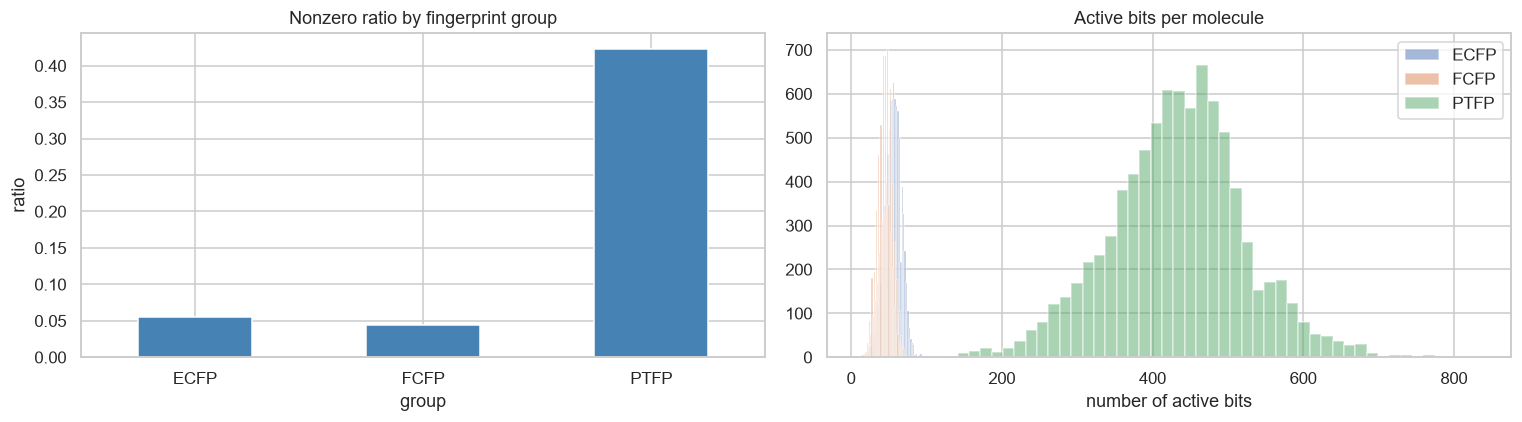

In [4]:
rows = []
for name, cols in FP_GROUPS.items():
    arr = df[cols].to_numpy(dtype=np.int8)
    rows.append({
        'group': name.upper(),
        'n_cols': len(cols),
        'nonzero_ratio': arr.mean(),
        'mean_bits_per_mol': arr.sum(axis=1).mean(),
        'constant_cols': int((arr.min(axis=0) == arr.max(axis=0)).sum()),
        'unique_vectors': pd.util.hash_pandas_object(df[cols], index=False).nunique(),
    })
summary = pd.DataFrame(rows).set_index('group')
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
summary['nonzero_ratio'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Nonzero ratio by fingerprint group')
axes[0].set_ylabel('ratio')
axes[0].tick_params(axis='x', rotation=0)

for name, cols in FP_GROUPS.items():
    bits = df[cols].sum(axis=1)
    axes[1].hist(bits, bins=50, alpha=0.5, label=name.upper())
axes[1].set_title('Active bits per molecule')
axes[1].set_xlabel('number of active bits')
axes[1].legend()
plt.tight_layout()
plt.show()

### 1-3. 비트 빈도와 희소성

상수 비트(항상 0 또는 1)와 극희귀 비트는 선형 모델에서 노이즈가 될 수 있습니다.  
트리 모델은 상수 비트만 제거해도 되지만, 선형 모델은 rare-bit 필터링을 별도로 검토합니다.

,min_prev,median_prev,max_prev,bits_eq_0,bits_lt_1pct,bits_lt_0.1pct,bits_gt_99pct
group,,,,,,,
ECFP,0.0040,0.0265,0.9928,0,98,0,1
FCFP,0.0002,0.0134,0.9984,0,422,23,2
PTFP,0.0007,0.2441,1.0000,0,34,1,166


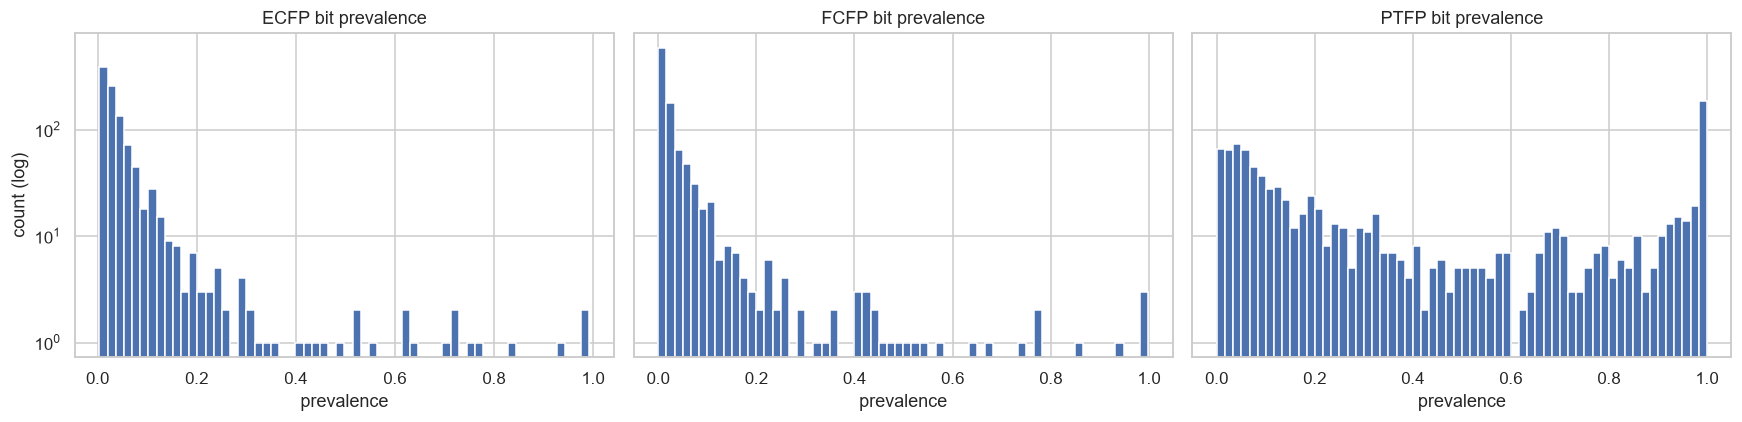

In [5]:
prev_rows = []
for name, cols in FP_GROUPS.items():
    prev = df[cols].mean(axis=0)
    prev_rows.append({
        'group': name.upper(),
        'min_prev': prev.min(),
        'median_prev': prev.median(),
        'max_prev': prev.max(),
        'bits_eq_0': int((prev == 0).sum()),
        'bits_lt_1pct': int((prev < 0.01).sum()),
        'bits_lt_0.1pct': int((prev < 0.001).sum()),
        'bits_gt_99pct': int((prev > 0.99).sum()),
    })
prev_summary = pd.DataFrame(prev_rows).set_index('group')
display(prev_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, cols) in zip(axes, FP_GROUPS.items()):
    prev = df[cols].mean(axis=0).clip(lower=1e-6)
    ax.hist(prev, bins=60, log=True)
    ax.set_title(f'{name.upper()} bit prevalence')
    ax.set_xlabel('prevalence')
axes[0].set_ylabel('count (log)')
plt.tight_layout()
plt.show()

## 2. 타깃(label)

`label`은 이진값이며, 클래스 비율은 1: 4,542 (54.4%), 0: 3,807 (45.6%)로 경미한 불균형입니다.  
Accuracy만 보면 소수 클래스의 성능을 놓칠 수 있으므로, 이후 ROC-AUC/PR-AUC/클래스별 Recall을 함께 봅니다.

,count,ratio
0 = toxic (Negative),3807,0.456
1 = non-toxic (Positive),4542,0.544


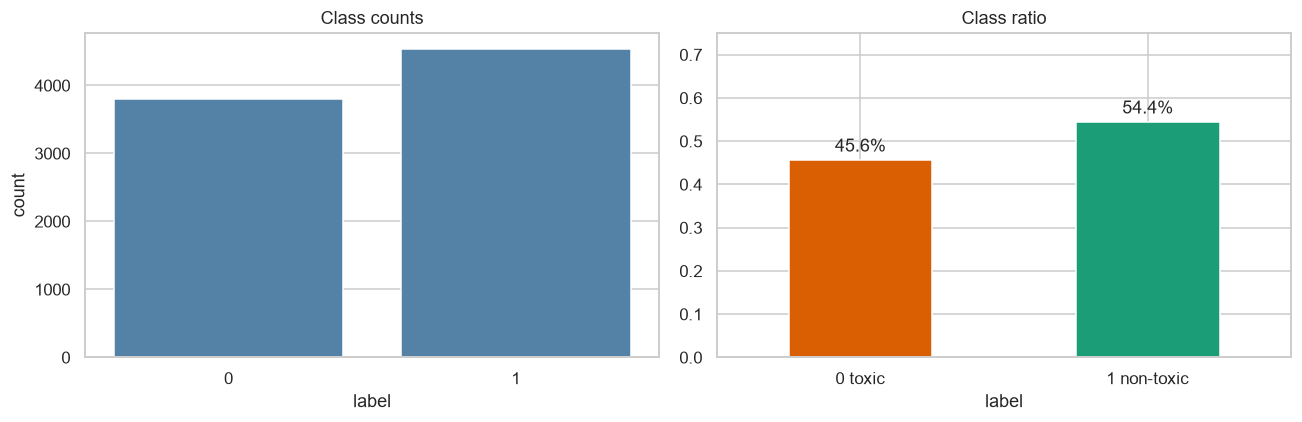

In [6]:
counts = df[TARGET].value_counts().sort_index()
ratio = df[TARGET].value_counts(normalize=True).sort_index()
class_table = pd.DataFrame({'count': counts, 'ratio': ratio})
class_table.index = ['0 = toxic (Negative)', '1 = non-toxic (Positive)']
display(class_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=TARGET, color='steelblue', ax=axes[0])
axes[0].set_title('Class counts')
axes[0].set_xlabel('label')

ratio.plot(kind='bar', ax=axes[1], color=['#d95f02', '#1b9e77'])
axes[1].set_title('Class ratio')
axes[1].set_xticklabels(['0 toxic', '1 non-toxic'], rotation=0)
axes[1].set_ylim(0, 0.75)
for i, v in enumerate(ratio):
    axes[1].text(i, v + 0.02, f'{v:.1%}', ha='center')
plt.tight_layout()
plt.show()

## 3. 기술자(descriptor)

`MolWt`, `clogp`, `sa_score`, `qed`는 SMILES에서 사전 계산된 값입니다.  
IQR 기준 이상치는 통계적 플래그일 뿐이므로, 화학적으로 타당한 큰 분자를 임의로 제거하지 않습니다.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
MolWt,8349.0,443.249,88.876,94.117,250.782,305.408,383.879,441.522,495.639,583.541,678.765,1242.488
clogp,8349.0,3.795,1.379,-4.049,0.796,1.645,2.875,3.735,4.653,6.095,7.501,9.429
sa_score,8349.0,3.188,0.728,1.282,1.931,2.191,2.663,3.093,3.594,4.521,5.265,7.309
qed,8349.0,0.559,0.186,0.024,0.170,0.250,0.425,0.556,0.701,0.867,0.918,0.947


,low,high,n_outliers,pct_outliers
feature,,,,
MolWt,216.2390,663.2790,130,0.0156
clogp,0.2075,7.3195,137,0.0164
sa_score,1.2682,4.9887,158,0.0189
qed,0.0128,1.1131,0,0.0000


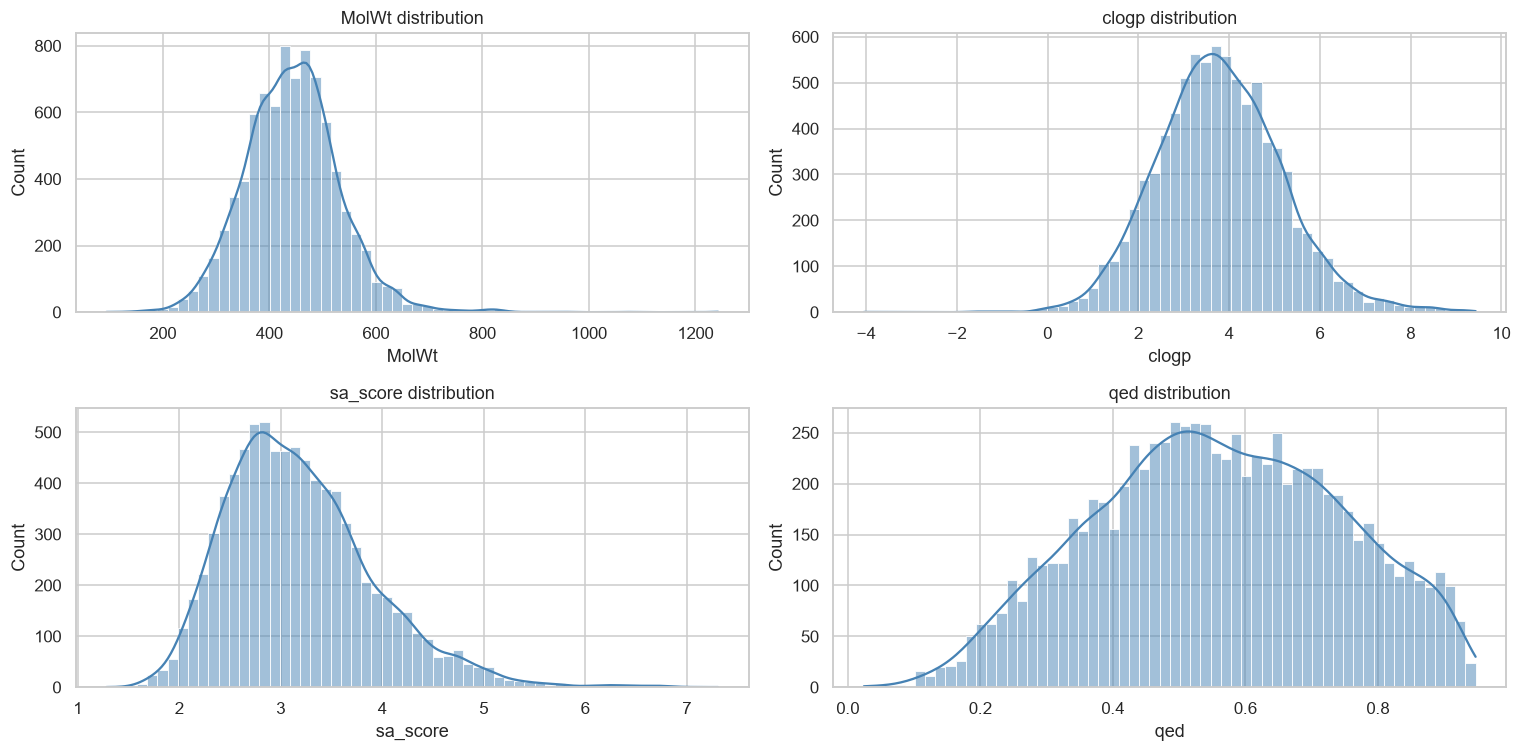

In [7]:
desc_stats = df[DESC].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
display(desc_stats.round(3))

out_rows = []
for c in DESC:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[c] < lo) | (df[c] > hi)
    out_rows.append({
        'feature': c,
        'low': lo,
        'high': hi,
        'n_outliers': int(mask.sum()),
        'pct_outliers': mask.mean(),
    })
display(pd.DataFrame(out_rows).set_index('feature').round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, c in zip(axes.ravel(), DESC):
    sns.histplot(x=df[c], bins=60, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{c} distribution')
plt.tight_layout()
plt.show()

correlation with label (point-biserial):
  MolWt    r=-0.006  p=6.02e-01
  clogp    r=-0.273  p=0.00e+00
  sa_score r=+0.078  p=1.02e-12
  qed      r=+0.084  p=1.85e-14


label,0,1
MolWt,443.803009,442.783997
clogp,4.206000,3.450000
sa_score,3.126000,3.240000
qed,0.542000,0.573000


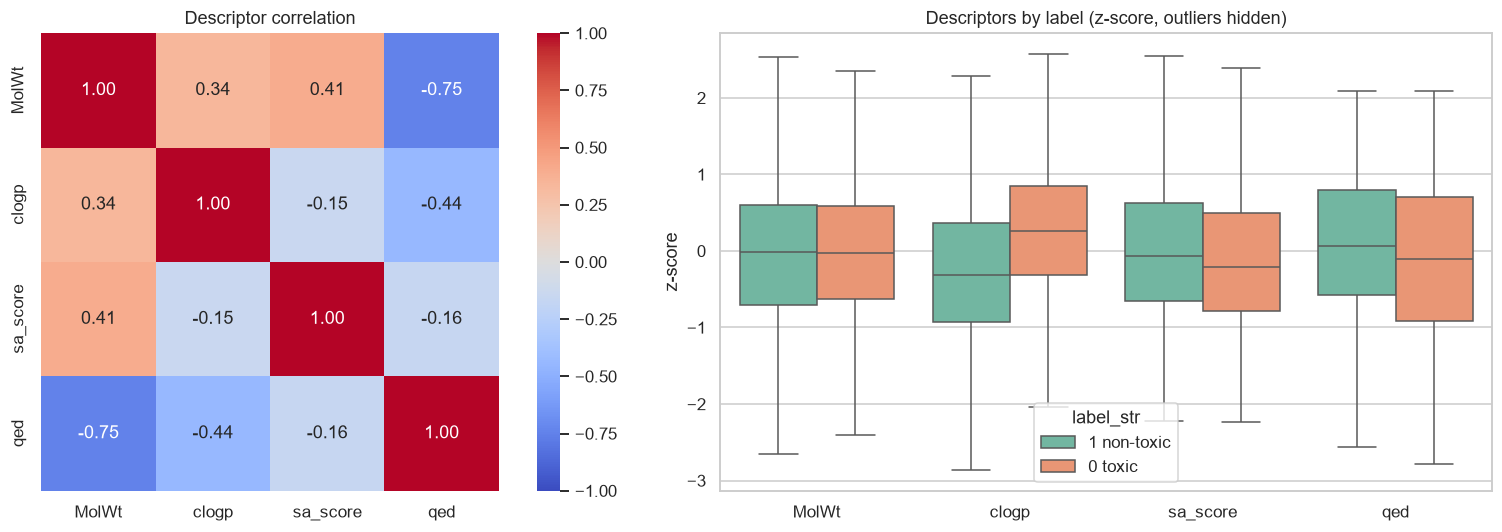

In [8]:
from scipy.stats import pointbiserialr

print('correlation with label (point-biserial):')
for c in DESC:
    r, p = pointbiserialr(df[TARGET], df[c])
    print(f'  {c:8s} r={r:+.3f}  p={p:.2e}')

display(df.groupby(TARGET)[DESC].mean().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
corr = df[DESC].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=axes[0])
axes[0].set_title('Descriptor correlation')

z = (df[DESC] - df[DESC].mean()) / df[DESC].std()
z[TARGET] = df[TARGET].values
z_long = z.melt(id_vars=TARGET, value_vars=DESC)
z_long['label_str'] = z_long[TARGET].map({0: '0 toxic', 1: '1 non-toxic'})
sns.boxplot(data=z_long, x='variable', y='value', hue='label_str',
            palette='Set2', showfliers=False, ax=axes[1])
axes[1].set_title('Descriptors by label (z-score, outliers hidden)')
axes[1].set_xlabel('')
axes[1].set_ylabel('z-score')
plt.tight_layout()
plt.show()

## 4. 지문(fingerprint)

지문 비트는 분자 구조의 부분구조를 나타내지만, 비트 인덱스 자체는 화학적 이름과 직접 매핑되지 않습니다.  
비트별 연관성은 탐색적으로 보고, 다중검정 보정(FDR)과 효과크기를 함께 확인합니다.

bits tested (prevalence 0.5%~99.5%): 2668
significant bits at FDR<0.05: 1039

Top +risk_diff (more common in non-toxic, label=1):


,bit,prev,p_y1,p_y0,risk_diff,q
807,ecfp_807,0.632,0.716,0.533,0.183,0.0
893,ecfp_893,0.555,0.632,0.463,0.169,0.0
650,ecfp_650,0.755,0.825,0.671,0.154,0.0
2101,ptfp_53,0.713,0.778,0.637,0.141,0.0
2804,ptfp_756,0.734,0.798,0.659,0.139,0.0
2653,ptfp_605,0.526,0.587,0.453,0.133,0.0
1025,fcfp_1,0.448,0.508,0.376,0.132,0.0
3032,ptfp_984,0.579,0.638,0.508,0.130,0.0



Top -risk_diff (more common in toxic, label=0):


,bit,prev,p_y1,p_y0,risk_diff,q
1042,fcfp_18,0.484,0.404,0.579,-0.174,0.0
1846,fcfp_822,0.465,0.392,0.552,-0.160,0.0
1570,fcfp_546,0.547,0.478,0.629,-0.150,0.0
767,ecfp_767,0.295,0.234,0.369,-0.135,0.0
1389,fcfp_365,0.443,0.391,0.505,-0.114,0.0
1695,fcfp_671,0.258,0.208,0.318,-0.110,0.0
887,ecfp_887,0.134,0.084,0.193,-0.109,0.0
80,ecfp_80,0.724,0.679,0.777,-0.098,0.0


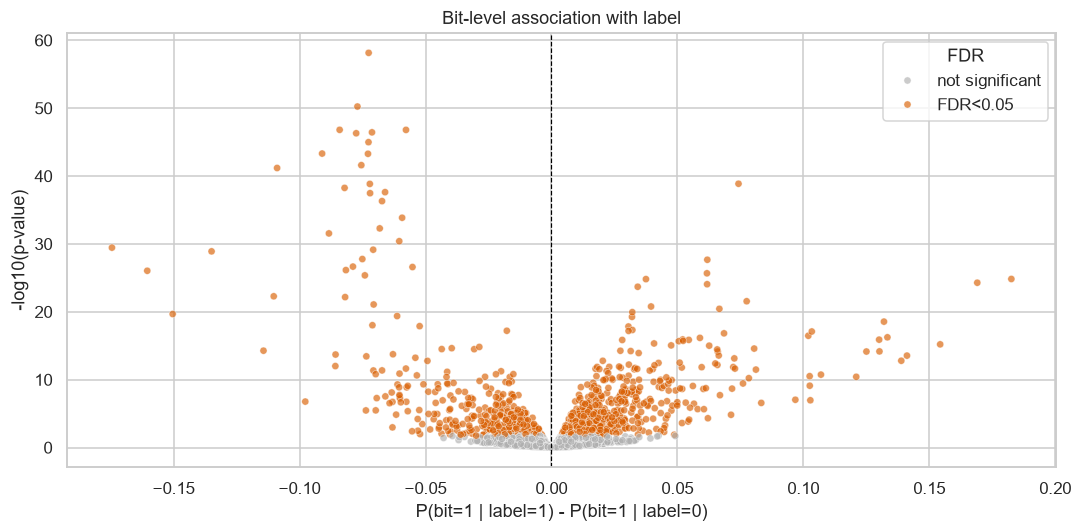

In [9]:
X = df[FP_COLS].to_numpy(dtype=np.int8)
y = df[TARGET].to_numpy(dtype=np.int8)

p1 = X[y == 1].mean(axis=0)
p0 = X[y == 0].mean(axis=0)
prev = X.mean(axis=0)
risk_diff = p1 - p0

from sklearn.feature_selection import chi2
chi, pval = chi2(X, y)
pval = np.nan_to_num(pval, nan=1.0, posinf=1.0)

# Benjamini-Hochberg FDR
m = len(pval)
order = np.argsort(pval)
ranked = pval[order] * m / np.arange(1, m + 1)
q_sorted = np.minimum.accumulate(ranked[::-1])[::-1]
q = np.empty(m)
q[order] = np.clip(q_sorted, 0, 1)

assoc = pd.DataFrame({
    'bit': FP_COLS,
    'prev': prev,
    'p_y1': p1,
    'p_y0': p0,
    'risk_diff': risk_diff,
    'chi2': chi,
    'p_value': pval,
    'q': q,
})
valid = (assoc['prev'] >= 0.005) & (assoc['prev'] <= 0.995)
print('bits tested (prevalence 0.5%~99.5%):', int(valid.sum()))
print('significant bits at FDR<0.05:', int(((assoc['q'] < 0.05) & valid).sum()))

show_cols = ['bit', 'prev', 'p_y1', 'p_y0', 'risk_diff', 'q']
print('\nTop +risk_diff (more common in non-toxic, label=1):')
display(assoc[valid].nlargest(8, 'risk_diff')[show_cols].round(3))
print('\nTop -risk_diff (more common in toxic, label=0):')
display(assoc[valid].nsmallest(8, 'risk_diff')[show_cols].round(3))

plot_df = assoc[valid].copy()
plot_df['neglog10p'] = -np.log10(np.clip(plot_df['p_value'], 1e-300, 1))
plot_df['significant'] = np.where(plot_df['q'] < 0.05, 'FDR<0.05', 'not significant')

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=plot_df, x='risk_diff', y='neglog10p', hue='significant',
                palette={'FDR<0.05': '#d95f02', 'not significant': '#b0b0b0'},
                s=22, alpha=0.65, ax=ax)
ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_title('Bit-level association with label')
ax.set_xlabel('P(bit=1 | label=1) - P(bit=1 | label=0)')
ax.set_ylabel('-log10(p-value)')
ax.legend(title='FDR')
plt.tight_layout()
plt.show()

,mean,median,p10,p90
pair,,,,
ECFP–FCFP,0.034,0.033,0.010,0.059
ECFP–PTFP,0.053,0.054,0.035,0.070
FCFP–PTFP,0.044,0.043,0.029,0.058


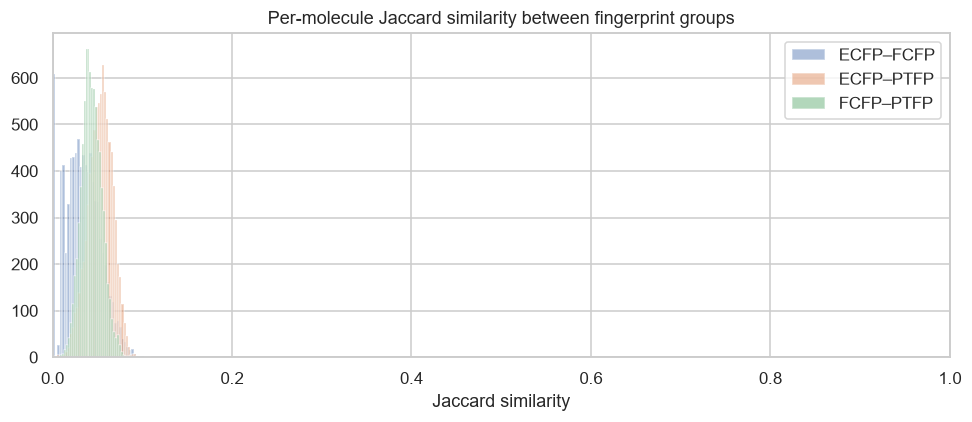

In [10]:
def jaccard(a, b):
    inter = np.logical_and(a, b).sum(axis=1)
    union = np.logical_or(a, b).sum(axis=1)
    return np.where(union > 0, inter / np.maximum(union, 1), 0.0)

A = {name: df[cols].to_numpy(dtype=bool) for name, cols in FP_GROUPS.items()}
pairs = [('ecfp', 'fcfp'), ('ecfp', 'ptfp'), ('fcfp', 'ptfp')]

rows = []
for a, b in pairs:
    j = jaccard(A[a], A[b])
    rows.append({
        'pair': f'{a.upper()}–{b.upper()}',
        'mean': j.mean(),
        'median': np.median(j),
        'p10': np.percentile(j, 10),
        'p90': np.percentile(j, 90),
    })
display(pd.DataFrame(rows).set_index('pair').round(3))

fig, ax = plt.subplots(figsize=(9, 4))
for a, b in pairs:
    ax.hist(jaccard(A[a], A[b]), bins=40, alpha=0.45, label=f'{a.upper()}–{b.upper()}')
ax.set_title('Per-molecule Jaccard similarity between fingerprint groups')
ax.set_xlabel('Jaccard similarity')
ax.set_xlim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

### 4-3. 중복 지문과 입체이성질체

정확히 같은 지문 벡터를 가진 분자가 242그룹/536행 존재합니다.  
ECFP/FCFP/PTFP는 입체화학(stereochemistry)을 구분하지 않으므로, 같은 2D 골격의 입체이성질체가 동일한 벡터로 collapse될 수 있습니다.  
아래 예시에서 실제로 어떤 분자들이 묶이는지 확인합니다.

In [11]:
mixed = dup_groups[dup_groups['n_labels'] > 1].sort_values('n', ascending=False)
same = dup_groups[(dup_groups['n_labels'] == 1) & (dup_groups['n'] > 1)].sort_values('n', ascending=False)

print('mixed-label duplicate groups:', len(mixed), '| rows:', int(mixed['n'].sum()))
display(mixed.head(5))

for title, group_id in [('Mixed-label example', mixed.index[0]),
                        ('Same-label example', same.index[0])]:
    print(f'\n{title}: group size={int(dup_groups.loc[group_id, "n"])}')
    display(df.loc[df['fp_group'] == group_id, ['SMILES', TARGET]].reset_index(drop=True))

mixed-label duplicate groups: 34 | rows: 75


,n,n_labels,labels
fp_group,,,
6141249008137424590,4,2,"(0, 1)"
2426555074042908826,3,2,"(0, 1)"
13803131179375911675,3,2,"(0, 1)"
11635679909974286190,3,2,"(0, 1)"
6275032531610739903,3,2,"(0, 1)"



Mixed-label example: group size=4


,SMILES,label
0,COc1ccc2nccc([C@H](O)[C@@H](O)[C@H]3CC[C@@H](C...,0
1,COc1ccc2nccc([C@@H](O)[C@H](O)[C@@H]3CC[C@H](C...,1
2,COc1ccc2nccc([C@@H](O)[C@H](O)[C@H]3CC[C@@H](C...,1
3,COc1ccc2nccc([C@H](O)[C@@H](O)[C@@H]3CC[C@H](C...,0



Same-label example: group size=5


,SMILES,label
0,C[C@H]1CCCN1[C@@H]2CCN(C2)c3ccc(NC(=O)c4cc(F)c...,0
1,C[C@@H]1CCCN1[C@H]2CCN(C2)c3ccc(NC(=O)c4cc(F)c...,0
2,C[C@H]1CCCN1[C@H]2CCN(C2)c3ccc(NC(=O)c4cc(F)cc...,0
3,CC1CCCN1C2CCN(C2)c3ccc(NC(=O)c4cc(F)ccc4C)c(C)c3,0
4,C[C@@H]1CCCN1[C@@H]2CCN(C2)c3ccc(NC(=O)c4cc(F)...,0


**해석**

- 정확히 같은 지문을 가진 그룹은 대부분 같은 골격의 입체이성질체입니다.
- 34그룹/75행은 **같은 지문인데 label이 0과 1로 혼재**합니다. 즉, 지문만으로는 구분할 수 없는 입체화학이 독성에 영향을 줄 수 있습니다.
- 따라서 중복 행을 무조건 삭제하지 말고, **CV에서 같은 `fp_group`을 같은 fold에 묶는 GroupKFold**를 사용해야 합니다.
- 입체화학이 중요한 과제라면 RDKit stereochemistry descriptor나 SMILES 기반 모델을 추가로 검토합니다.

## 5. SMILES · 입체화학

SMILES는 분자 식별자입니다. 문자열 자체를 기본 피처로 쓰기보다는, 길이·토큰 구성·입체화학 표시(`@`) 같은 요약 특성을 확인합니다.

count    8349.0
mean       56.6
std        15.0
min         9.0
25%        47.0
50%        55.0
75%        64.0
max       249.0


,count,mean,toxic_rate
has_stereo,,,
False,4660,0.507,0.493
True,3689,0.591,0.409


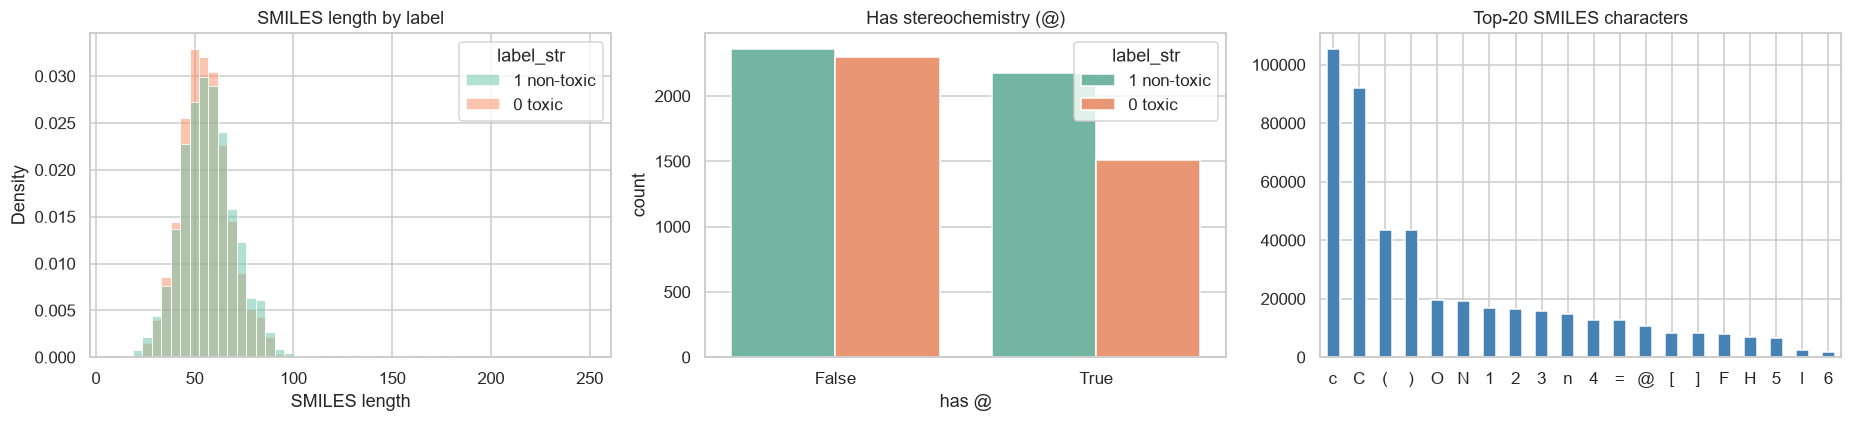

In [12]:
smi = df['SMILES'].astype(str)
plot_df = pd.DataFrame({
    'smiles_len': smi.str.len(),
    'n_at': smi.str.count('@'),
    TARGET: df[TARGET].values,
})
plot_df['has_stereo'] = plot_df['n_at'] > 0
plot_df['label_str'] = plot_df[TARGET].map({0: '0 toxic', 1: '1 non-toxic'})

print(plot_df['smiles_len'].describe().round(1).to_string())
stereo_table = plot_df.groupby('has_stereo')[TARGET].agg(['count', 'mean'])
stereo_table['toxic_rate'] = 1 - stereo_table['mean']
display(stereo_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=plot_df, x='smiles_len', hue='label_str', bins=50,
             stat='density', common_norm=False, palette='Set2', ax=axes[0])
axes[0].set_title('SMILES length by label')
axes[0].set_xlabel('SMILES length')

sns.countplot(data=plot_df, x='has_stereo', hue='label_str',
              palette='Set2', ax=axes[1])
axes[1].set_title('Has stereochemistry (@)')
axes[1].set_xlabel('has @')

chars = Counter(''.join(smi.tolist()))
char_s = pd.Series(chars).sort_values(ascending=False).head(20)
char_s.plot(kind='bar', ax=axes[2], color='steelblue')
axes[2].set_title('Top-20 SMILES characters')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


**SMILES 요약**

- 입체화학 표시(`@`)가 있는 분자는 3,689개(44.2%)입니다.
- 이들의 toxic rate는 40.9%, 표시가 없는 분자는 49.3%입니다. 이 데이터에서는 입체화학 표시가 있는 분자의 독성 비율이 다소 낮지만, 단순 연관이므로 인과관계로 해석하지 않습니다.
- SMILES 길이는 9~249자(평균 56.6)이며, label별 평균은 55.5자(0) vs 57.5자(1)로 작은 차이입니다.


In [13]:
try:
    from rdkit import Chem
    RDKIT_AVAILABLE = True
except Exception:
    RDKIT_AVAILABLE = False

if not RDKIT_AVAILABLE:
    print('RDKit not installed -> skipping SMILES validity / scaffold checks.')
else:
    mols = [Chem.MolFromSmiles(s) for s in df['SMILES']]
    valid = np.array([m is not None for m in mols])
    print(f'valid SMILES: {valid.mean():.1%} ({valid.sum()}/{len(valid)})')
    display(pd.Series(valid).value_counts().rename(index={True: 'valid', False: 'invalid'}))

RDKit not installed -> skipping SMILES validity / scaffold checks.


## 6. 모델링 준비도 (가벼운 베이스라인)

이 섹션은 최종 모델이 아니라, EDA에서 확인한 신호가 실제 예측으로 이어지는지 확인하는 **준비도 점검**입니다.  
- 그룹 CV: 같은 지문 벡터(입체이성질체 포함)를 같은 fold에 묶어 누수를 줄입니다.
- 랜덤 CV와 비교해 누수 영향이 얼마나 되는지 확인합니다.
- 모델은 LogisticRegression 하나만 사용하고, 하이퍼파라미터 튜닝은 하지 않습니다.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_desc = df[DESC].to_numpy(dtype=np.float32)
X_ecfp = sparse.csr_matrix(df[FP_GROUPS['ecfp']].to_numpy(dtype=np.int8))
X_fp = sparse.csr_matrix(df[FP_COLS].to_numpy(dtype=np.int8))
X_all = df[DESC + FP_COLS]

y = df[TARGET].to_numpy(dtype=np.int8)
groups = df['fp_group'].to_numpy()

cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_random = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows = []
for i, (tr, va) in enumerate(cv_group.split(X_desc, y, groups), start=1):
    fold_rows.append({
        'fold': i,
        'n_train': len(tr),
        'n_valid': len(va),
        'valid_non_toxic_rate': y[va].mean(),
    })
display(pd.DataFrame(fold_rows).round(3))

def make_lr():
    return LogisticRegression(max_iter=2000, solver='liblinear', C=1.0,
                              random_state=RANDOM_STATE)

prep = ColumnTransformer(
    [('desc', StandardScaler(), DESC),
     ('fp', 'passthrough', FP_COLS)],
    sparse_threshold=0.3,
)

models = {
    'Dummy (prior)': DummyClassifier(strategy='prior'),
    'Descriptors': Pipeline([('scaler', StandardScaler()), ('clf', make_lr())]),
    'ECFP': make_lr(),
    'All fingerprints': make_lr(),
    'Descriptors + all FP': Pipeline([('prep', prep), ('clf', make_lr())]),
}
X_by_model = {
    'Dummy (prior)': X_desc,
    'Descriptors': X_desc,
    'ECFP': X_ecfp,
    'All fingerprints': X_fp,
    'Descriptors + all FP': X_all,
}

scoring = {
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
    'toxic_recall': make_scorer(recall_score, pos_label=0),
    'accuracy': 'accuracy',
}
print('data matrices ready:', X_desc.shape, X_ecfp.shape, X_fp.shape, X_all.shape)

,fold,n_train,n_valid,valid_non_toxic_rate
0,1,6679,1670,0.544
1,2,6679,1670,0.544
2,3,6679,1670,0.544
3,4,6680,1669,0.544
4,5,6679,1670,0.544


data matrices ready: (8349, 4) (8349, 1024) (8349, 3072) (8349, 3076)


In [15]:
results = {}
for scheme, cv, use_groups in [('Group', cv_group, True), ('Random', cv_random, False)]:
    for name, model in models.items():
        print(f'{scheme:6s} | {name:24s}', end=' ... ', flush=True)
        res = cross_validate(
            model,
            X_by_model[name],
            y,
            cv=cv,
            groups=groups if use_groups else None,
            scoring=scoring,
            n_jobs=1,
            error_score='raise',
        )
        results[(scheme, name)] = res
        print('done')

Group  | Dummy (prior)            ... done
Group  | Descriptors              ... done
Group  | ECFP                     ... done
Group  | All fingerprints         ... done
Group  | Descriptors + all FP     ... done
Random | Dummy (prior)            ... done
Random | Descriptors              ... done
Random | ECFP                     ... done
Random | All fingerprints         ... done
Random | Descriptors + all FP     ... done


Group CV (mean):


,ROC-AUC,PR-AUC,F1,Precision(1),Recall(1),Toxic recall(0),Accuracy
model,,,,,,,
Dummy (prior),0.500,0.544,0.705,0.544,1.000,0.000,0.544
Descriptors,0.668,0.709,0.673,0.632,0.721,0.499,0.620
ECFP,0.790,0.807,0.739,0.733,0.745,0.676,0.713
All fingerprints,0.832,0.843,0.778,0.775,0.781,0.729,0.757
Descriptors + all FP,0.836,0.846,0.781,0.779,0.784,0.733,0.761


Random vs Group CV - Descriptors + all FP:


,ROC-AUC,PR-AUC,F1,Precision(1),Recall(1),Toxic recall(0),Accuracy
scheme,,,,,,,
Group,0.836,0.846,0.781,0.779,0.784,0.733,0.761
Random,0.835,0.843,0.785,0.783,0.787,0.740,0.766


label=1 prevalence (PR-AUC baseline): 0.544


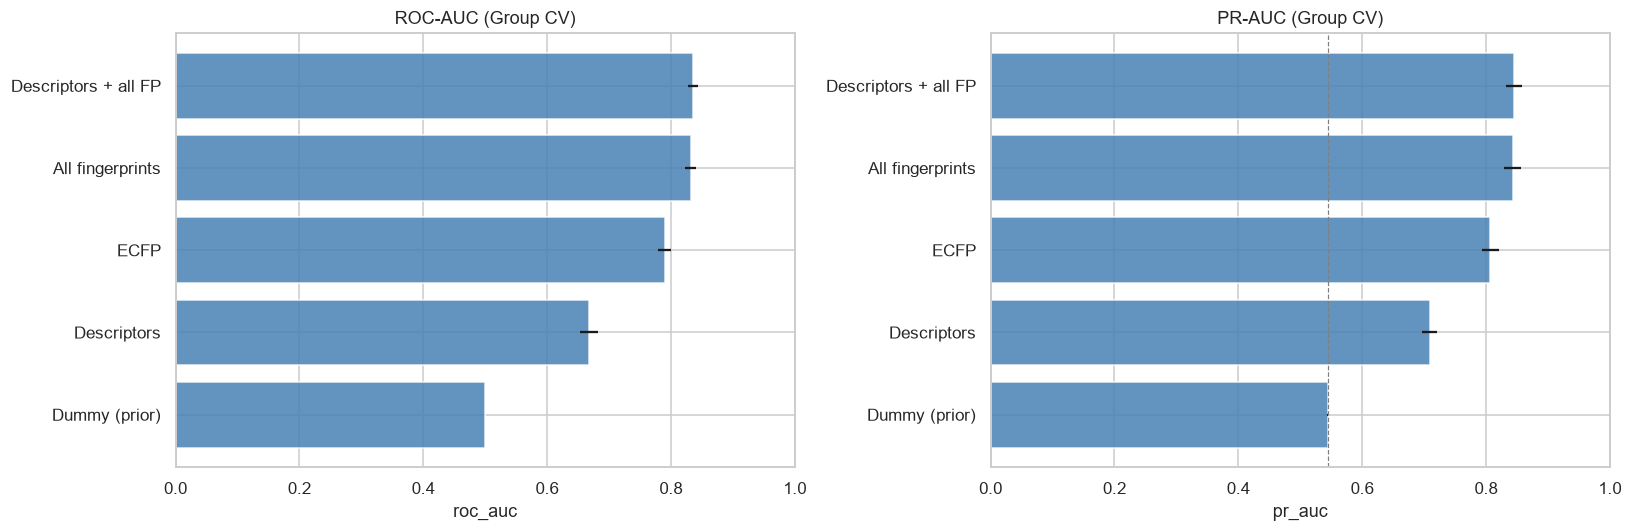

In [16]:
summary_rows = []
for (scheme, name), res in results.items():
    row = {'scheme': scheme, 'model': name}
    for metric in scoring:
        row[metric] = res[f'test_{metric}'].mean()
        row[f'{metric}_std'] = res[f'test_{metric}'].std()
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)

show_metrics = ['roc_auc', 'pr_auc', 'f1', 'precision', 'recall', 'toxic_recall', 'accuracy']
rename = {
    'roc_auc': 'ROC-AUC',
    'pr_auc': 'PR-AUC',
    'f1': 'F1',
    'precision': 'Precision(1)',
    'recall': 'Recall(1)',
    'toxic_recall': 'Toxic recall(0)',
    'accuracy': 'Accuracy',
}

print('Group CV (mean):')
display(
    summary[summary['scheme'] == 'Group'][['model'] + show_metrics]
    .set_index('model').rename(columns=rename).round(3)
)

print('Random vs Group CV - Descriptors + all FP:')
display(
    summary[summary['model'] == 'Descriptors + all FP'][['scheme'] + show_metrics]
    .set_index('scheme').rename(columns=rename).round(3)
)
print('label=1 prevalence (PR-AUC baseline):', round(float(y.mean()), 3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(
    axes,
    ['roc_auc', 'pr_auc'],
    ['ROC-AUC (Group CV)', 'PR-AUC (Group CV)'],
):
    d = summary[summary['scheme'] == 'Group'].sort_values(metric)
    ax.barh(d['model'], d[metric], xerr=d[f'{metric}_std'],
            color='steelblue', alpha=0.85)
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_xlabel(metric)
    if metric == 'pr_auc':
        ax.axvline(float(y.mean()), color='gray', ls='--', lw=0.8)
plt.tight_layout()
plt.show()

OOF accuracy:      0.7612
OOF ROC-AUC:       0.8358
OOF PR-AUC:        0.8450
OOF F1 (label=1):  0.7814
Toxic recall(0):   0.7334
Toxic precision(0):0.7404


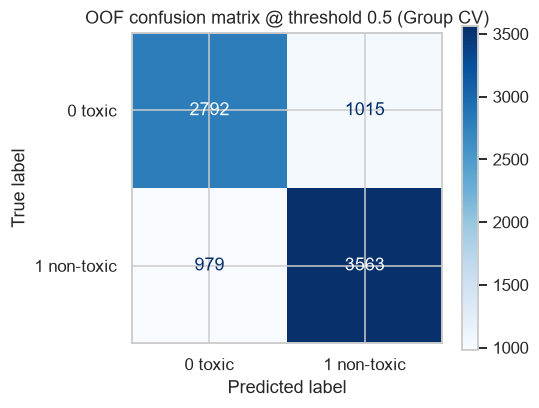


False negatives (true toxic=0, predicted 1):


,SMILES,label,pred,p_non_toxic
8332,C[C@@H]1O[C@@H](O[C@H]2C[C@@H](O)[C@]3(CO)[C@H...,0,1,1.000000
136,O=C1CCC(=NN1)c2ccc(Nc3ccncc3)cc2,0,1,0.999999
8311,CN1C(=O)N(C(=O)c2cccc(F)c12)c3cccc(c3C)c4c(F)c...,0,1,0.999997
3841,OCCNCCNc1ccc(NCCNCCO)c2C(=O)c3c(O)ccc(O)c3C(=O...,0,1,0.999983
6924,COc1cc(Nc2ncc(F)c(Nc3ccc4OC(C)(C)C(=O)N(COP(=O...,0,1,0.999978



False positives (true non-toxic=1, predicted 0):


,SMILES,label,pred,p_non_toxic
8229,CN1C(=O)c2c(nc(Cc3ccc(cc3)c4ccccc4)n2Cc5ccccc5...,1,0,7.829875e-09
2590,CC1(C)CN2C(=CSC2=N1)CS\C(=N/C3CCCCC3)\NC4CCCCC4,1,0,3.251411e-05
4803,CN(C)CCCOc1ccc(CCNC(=O)c2cc(Br)c[nH]2)cc1Br,1,0,3.607463e-05
6052,CC(=O)Nc1cccc(c1)C2CCN(CCCN3N=C(c4ccc(F)c(F)c4...,1,0,3.927889e-05
614,C1CN2CCC1C(C2)c3oc(nn3)c4oc(cc4)c5cccnc5,1,0,4.371106e-05


In [17]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_predict

combined = models['Descriptors + all FP']
proba = cross_val_predict(
    combined, X_all, y, groups=groups, cv=cv_group,
    method='predict_proba', n_jobs=1,
)
pred = (proba[:, 1] >= 0.5).astype(int)

print(f'OOF accuracy:      {accuracy_score(y, pred):.4f}')
print(f'OOF ROC-AUC:       {roc_auc_score(y, proba[:, 1]):.4f}')
print(f'OOF PR-AUC:        {average_precision_score(y, proba[:, 1]):.4f}')
print(f'OOF F1 (label=1):  {f1_score(y, pred):.4f}')
print(f'Toxic recall(0):   {recall_score(y, pred, pos_label=0):.4f}')
print(f'Toxic precision(0):{precision_score(y, pred, pos_label=0):.4f}')

cm = confusion_matrix(y, pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['0 toxic', '1 non-toxic']).plot(
    cmap='Blues', values_format='d', ax=ax
)
ax.set_title('OOF confusion matrix @ threshold 0.5 (Group CV)')
plt.tight_layout()
plt.show()

err = df.loc[pred != y, ['SMILES', TARGET]].copy()
err['pred'] = pred[pred != y]
err['p_non_toxic'] = proba[pred != y, 1]
print('\nFalse negatives (true toxic=0, predicted 1):')
display(err[err[TARGET] == 0].nlargest(5, 'p_non_toxic'))
print('\nFalse positives (true non-toxic=1, predicted 0):')
display(err[err[TARGET] == 1].nsmallest(5, 'p_non_toxic'))

Top coefficients (positive -> label 1 / non-toxic):


,coef
fp__fcfp_926,1.7359
fp__fcfp_399,1.7154
fp__ptfp_561,1.6912
fp__fcfp_407,1.6081
fp__fcfp_508,1.5713
fp__ecfp_28,1.5696
fp__fcfp_749,1.4922
fp__ecfp_254,1.4892
fp__fcfp_228,1.4778
fp__ecfp_704,1.4672


,coef
desc__clogp,-1.9156
fp__ptfp_183,-1.7374
fp__ptfp_947,-1.5355
fp__ptfp_117,-1.5315
fp__ecfp_438,-1.5287
fp__fcfp_623,-1.4689
fp__ptfp_446,-1.4511
fp__ecfp_0,-1.4414
fp__fcfp_896,-1.4299
fp__fcfp_271,-1.4178


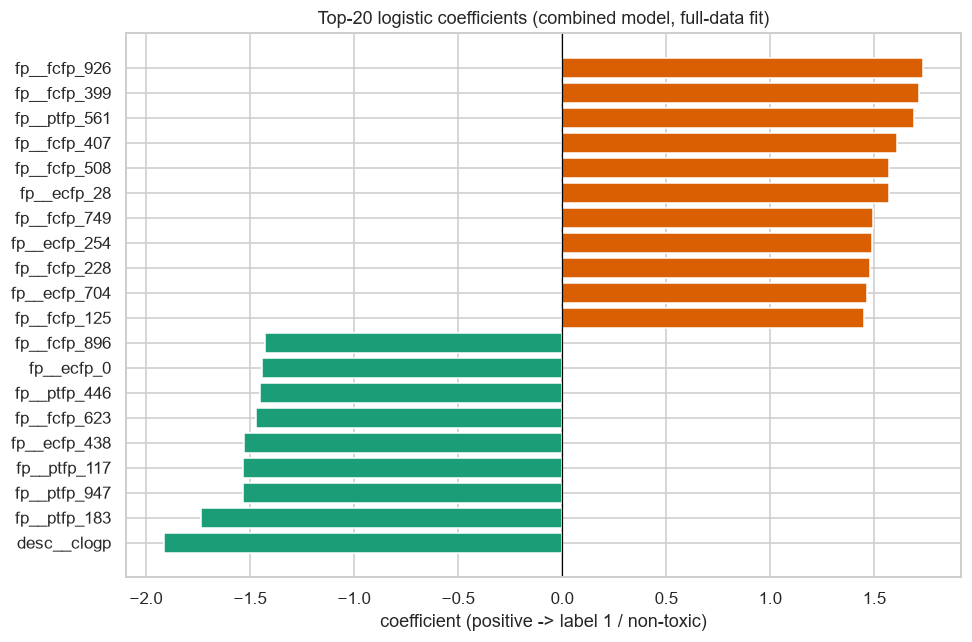

Note: fingerprint bit indices are arbitrary; mapping to substructures requires RDKit bit info.


In [18]:
combined.fit(X_all, y)
prep_fitted = combined.named_steps['prep']
clf_fitted = combined.named_steps['clf']
feature_names = prep_fitted.get_feature_names_out()
coef = pd.Series(clf_fitted.coef_[0], index=feature_names)

top = coef.abs().sort_values(ascending=False).head(20)
top_df = pd.DataFrame({
    'feature': top.index,
    'coef': coef.loc[top.index].values,
}).sort_values('coef')

print('Top coefficients (positive -> label 1 / non-toxic):')
display(coef.sort_values(ascending=False).head(10).round(4).to_frame('coef'))
display(coef.sort_values().head(10).round(4).to_frame('coef'))

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#d95f02' if v > 0 else '#1b9e77' for v in top_df['coef']]
ax.barh(top_df['feature'], top_df['coef'], color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Top-20 logistic coefficients (combined model, full-data fit)')
ax.set_xlabel('coefficient (positive -> label 1 / non-toxic)')
plt.tight_layout()
plt.show()

print('Note: fingerprint bit indices are arbitrary; mapping to substructures requires RDKit bit info.')

## 7. 결론 및 모델링 제언

### 데이터 품질 요약

| 이슈 | 내용 | 조치 |
|---|---|---|
| 결측 | 0 | imputation 불필요 |
| SMILES 중복 | 0 | 식별자로 사용 가능 |
| PTFP 상수 컬럼 | 49개 | 모델링 전 제거 |
| 중복 지문 | 242그룹 / 536행 | 삭제하지 말고 `fp_group`으로 묶어 GroupKFold |
| 혼재 라벨 그룹 | 34그룹 / 75행 | 입체화학 한계로 기록, 별도 분석 권장 |
| 지문 희소도 | ECFP 5.5%, FCFP 4.4%, PTFP 42.4% | 선형 모델은 rare-bit 필터링 검토 |
| 라벨 극성 | 1 = non-toxic, 0 = toxic (PDF 기준) | 지표 해석 시 반드시 확인 |
| 기술자 신호 | `clogp` r=-0.273, `qed` +0.084, `sa_score` +0.078, `MolWt` -0.006 | `clogp` 중심으로 해석하되 과대해석 금지 |

### 베이스라인 결과 (Group CV, 5-fold)

| 모델 | ROC-AUC | PR-AUC | F1 (label=1) | Toxic recall(0) |
|---|---:|---:|---:|---:|
| Dummy (prior) | 0.500 | 0.544 | 0.705 | 0.000 |
| Descriptors | 0.668 | 0.709 | 0.673 | 0.499 |
| ECFP | 0.790 | 0.807 | 0.739 | 0.676 |
| All fingerprints | 0.832 | 0.843 | 0.778 | 0.729 |
| Descriptors + all FP | **0.836** | **0.846** | **0.781** | **0.733** |

- 지문이 기술자보다 훨씬 강한 신호를 제공합니다.
- ECFP만으로도 ROC-AUC 0.79 수준이며, FCFP/PTFP를 더하면 0.83까지 오릅니다.
- 기술자의 추가 이득은 작지만(≈0.004), 해석 가능성이 높아 함께 두는 것이 좋습니다.
- Random CV와 Group CV의 ROC-AUC 차이는 0.001, F1 차이는 0.004, toxic recall 차이는 0.007로 작았습니다. 다만 입체이성질체 중복 구조가 있으므로 **Group CV를 기본**으로 보고합니다.

### 모델링 제언

1. **피처**
   - 기본: ECFP + FCFP + 기술자
   - PTFP는 dense(42% nonzero)이므로 포함/제외 ablation으로 기여도 확인
   - 상수 비트 제거, 선형 모델은 rare-bit(예: prevalence < 1%) 필터링 검토
2. **모델**
   - LogisticRegression은 강한 베이스라인
   - 이후 LightGBM/XGBoost 등 비선형 모델과 비교
   - 클래스 불균형은 경미하므로 `class_weight='balanced'`는 선택적으로 실험
3. **검증**
   - `StratifiedGroupKFold` by `fp_group` 기본
   - 가능하면 RDKit Murcko scaffold 기반 split도 비교
   - 랜덤 CV 결과만 보고 과대평가하지 않기
4. **지표**
   - ROC-AUC, PR-AUC, F1, Precision/Recall
   - **독성(label=0) recall**과 specificity를 별도로 보고
   - Accuracy는 참고용 (majority baseline 54.4%)
5. **Threshold**
   - 기본 0.5는 탐색용
   - 안전 목적이면 독성 recall을 우선해 threshold 조정
6. **제출**
   - `predict_input.csv`는 927행, `label` 없음
   - 출력은 `SMILES,label` 형식
   - 라벨 극성을 뒤집지 않도록 주의 (1=non-toxic, 0=toxic)

### 한계

- ECFP/FCFP/PTFP는 입체화학을 구분하지 못합니다. 같은 지문·다른 라벨 그룹이 그 증거입니다.
- RDKit이 없으므로 scaffold/validity 분석은 optional로 남겨두었습니다.
- 라벨 의미는 PDF 기준이며, 데이터만으로 검증할 수 없습니다.
- 외부 테스트셋이 없으므로 Group CV 결과가 일반화 성능을 보장하지 않습니다.

## 8. Optional: `predict_input.csv`

현재 폴더에는 `predict_input.csv`가 없습니다. 파일이 제공되면 아래 셀에서 스키마만 확인합니다.  
이 EDA 노트북에서는 제출 파일을 생성하지 않고, 최종 모델링 노트북/스크립트에서 생성합니다.

In [19]:
if PREDICT_PATH.exists():
    pred_head = pd.read_csv(PREDICT_PATH, nrows=5)
    print('predict_input.csv shape (first 5 rows):', pred_head.shape)
    print('columns (first 10):', pred_head.columns.tolist()[:10])
    print('label present:', 'label' in pred_head.columns)
    display(pred_head.head())
else:
    print('predict_input.csv not found -> optional cell skipped.')

predict_input.csv not found -> optional cell skipped.
